# 05 Pressure definition

**Objective.** Define pressure as leverage, show why thresholds fail and give independent evidence that players feel it.

**Inputs.** pressure/output, balls_pressure.parquet and leverage tables.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. Why thresholds fail

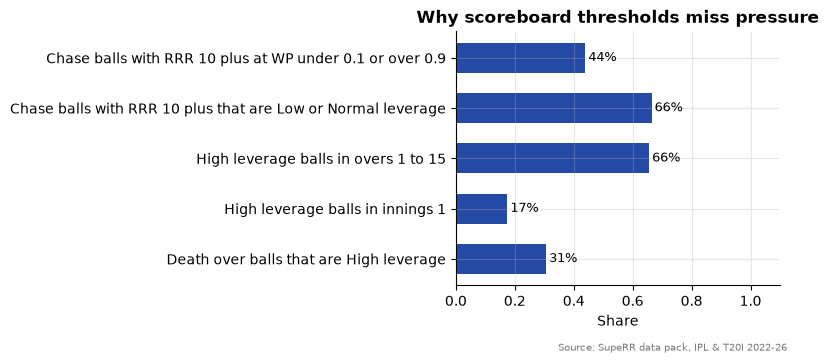

,check,share
0,Chase balls with RRR 10 plus at WP under 0.1 o...,0.439519
1,Chase balls with RRR 10 plus that are Low or N...,0.664292
2,High leverage balls in overs 1 to 15,0.655835
3,High leverage balls in innings 1,0.174872
4,Death over balls that are High leverage,0.306150


In [2]:
from pressure import plots as p2, leverage
b = read_parquet("pressure", "balls_pressure.parquet")
p2.threshold_vs_li(); plt.show()
read_table("pressure", "li_threshold_comparison.csv")

## Step 2. Leverage on one worked example ball

In [3]:
ex = b[(b.innings == 2) & (b.pressure_tier == "Extreme")].iloc[0]
rates = read_table("pressure", "li_outcome_rates.csv").set_index(["comp_type", "phase", "wband"]).loc[
    (ex.comp_type, ex.phase, leverage.wkt_bucket(pd.Series([ex.wkts_before])).iat[0])]
print(f"Match {ex.match_id}, over {ex.over_no}, need {ex.runs_needed:.0f} off {ex.balls_left} with {9 - ex.wkts_before + 1} wickets in hand")
print(f"WP before {ex.wp_pre:.3f}, raw leverage {ex.raw_li:.4f}, LI {ex.li:.2f}, tier {ex.pressure_tier}")
rates.round(3)

Match 13512, over 20.0, need 8 off 1.0 with 2.0 wickets in hand
WP before 0.105, raw leverage 0.1020, LI 8.70, tier Extreme


dot       0.257
1         0.333
2         0.083
3         0.003
4         0.105
6         0.067
wicket    0.100
extra     0.052
Name: (T20I_full, DEATH, 6-10), dtype: float64

## Step 3. LI heatmaps by wickets down

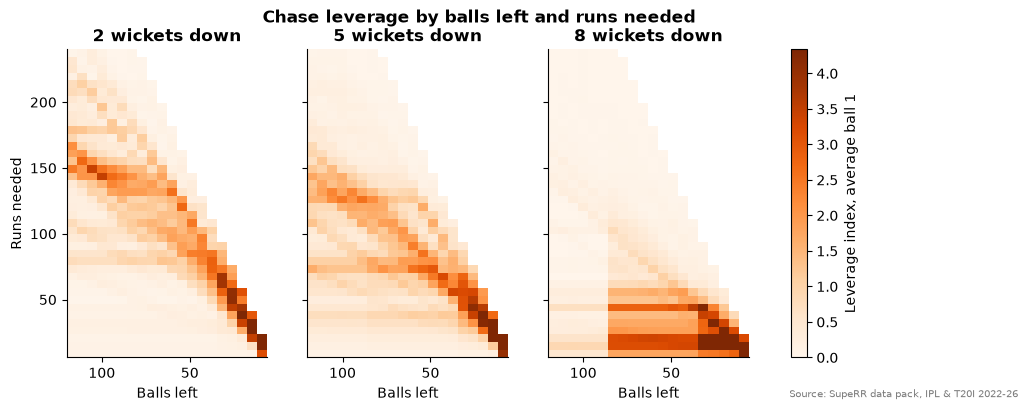

In [4]:
p2.li_heatmap(); plt.show()

## Step 4. LI by over and innings

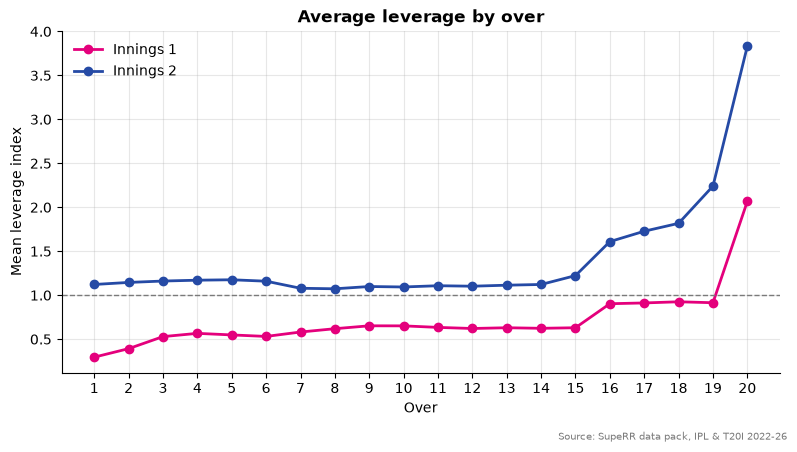

In [5]:
p2.li_by_over(); plt.show()

## Step 5. Share of pressure balls by phase, innings and batting slot

In [6]:
display(b.groupby("phase")["is_pressure"].mean().rename("pressure share").to_frame().T)
display(b.groupby("innings")["is_pressure"].mean().rename("pressure share").to_frame().T)
b.groupby("batting_order")["is_pressure"].mean().rename("pressure share").to_frame().T

phase,DEATH,MID,PP
pressure share,0.30615,0.176144,0.159049


innings,1,2
pressure share,0.067102,0.344685


batting_order,1,2,3,4,5,6,7,8,9,10,11,12,13
pressure share,0.152802,0.160001,0.177508,0.208289,0.238052,0.245334,0.273978,0.32989,0.180106,0.149063,0.15,0.529412,0.555556


## Step 6. Three match worms with leverage shading

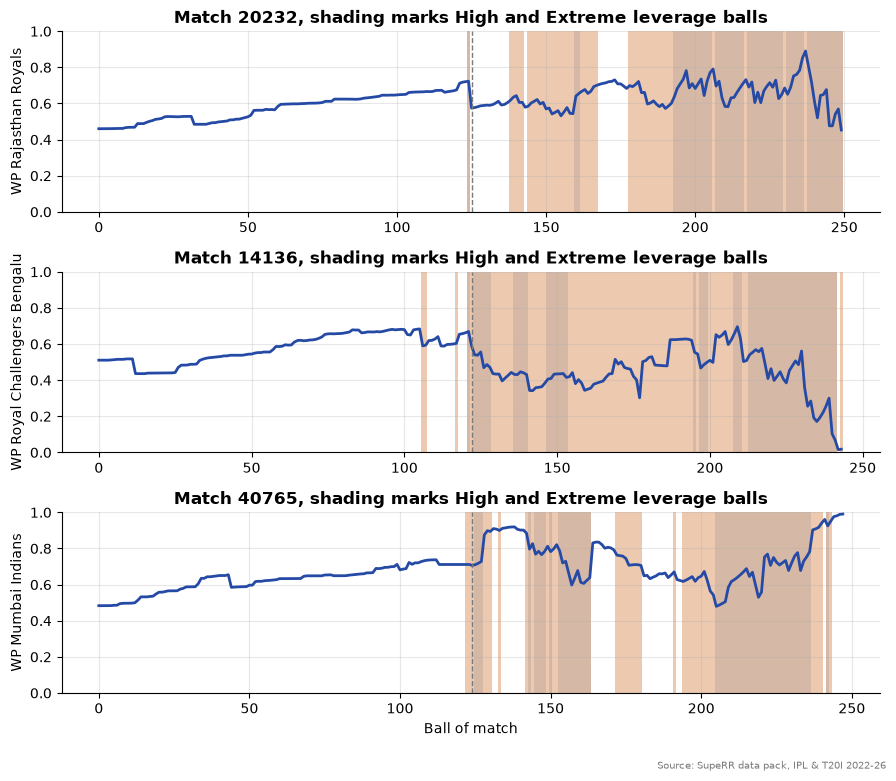

In [7]:
p2.worms(b); plt.show()

## Step 7. Separation, actual WP swing by tier

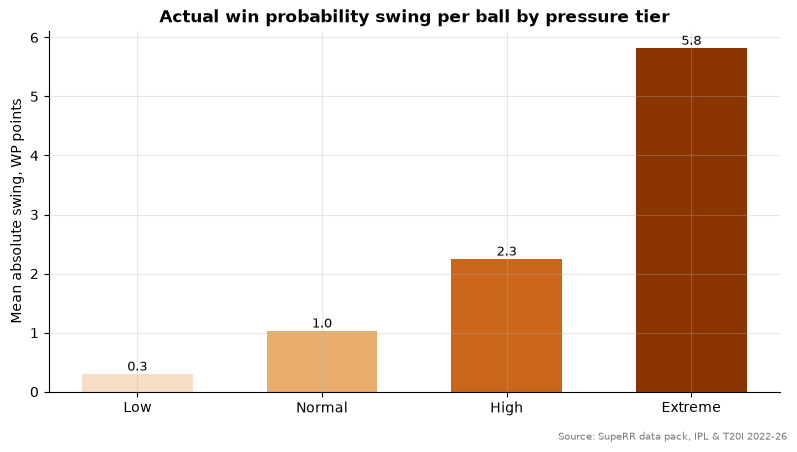

,mean_abs_dwp_high,mean_abs_dwp_normal,ratio,ks_stat,ks_p
0,0.031469,0.010361,3.037249,0.383351,0.0


In [8]:
p2.dwp_by_tier(b); plt.show()
read_table("pressure", "li_separation.csv")

## Step 8. Behavioural validation, tempo and execution

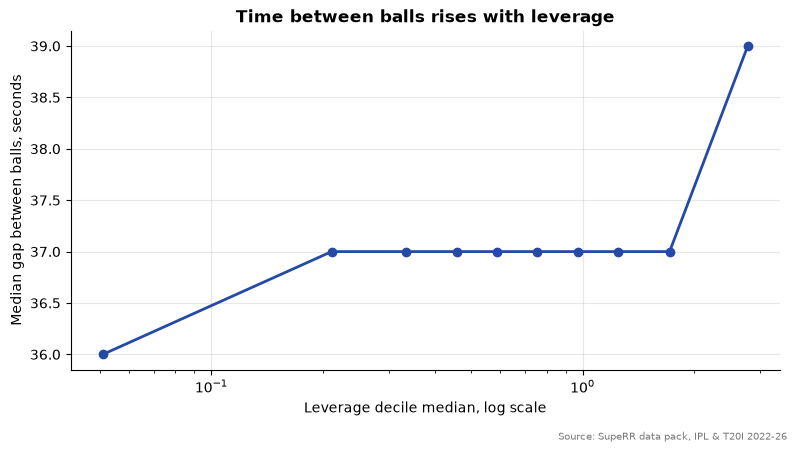

,signal,normal_raw,pressure_raw,normal_matched,pressure_matched,matched_diff
0,"Gap between balls, seconds",41.939959,44.033359,43.007578,44.033359,1.025781
1,Pace death full toss share,0.125639,0.131240,0.141141,0.131240,-0.009901
2,Pace death yorker share,0.090584,0.098637,0.095687,0.098637,0.002950
3,Death aggressive stroke share,0.135959,0.138866,0.143920,0.138866,-0.005054


In [9]:
p2.tempo(); plt.show()
read_table("pressure", "li_behaviour_checks.csv")

## Step 9. League-wide pressure tax

In [10]:
read_table("pressure", "pressure_tax.csv")

,metric,normal,pressure,diff
0,runs per ball,1.466911,1.459405,-0.007506
1,boundary rate,0.194331,0.188865,-0.005466
2,dot rate,0.338396,0.331560,-0.006835
3,wicket rate,0.063181,0.064719,0.001538


## Key findings

In [11]:
t = read_table("pressure", "li_threshold_comparison.csv").set_index("check")["share"]
s = read_table("pressure", "li_separation.csv").iloc[0]
ts = read_table("pressure", "tempo_summary.csv").iloc[0]
display(Markdown(f'''
- {t.iloc[0]:.0%} of chase balls with RRR 10 plus are already decided.
- {t.loc["High leverage balls in overs 1 to 15"]:.0%} of pressure balls come in overs 1 to 15.
- {t.loc["High leverage balls in innings 1"]:.0%} of pressure balls are in the first innings, low because first innings WP is hard to predict and so stays flat.
- Actual WP swing is {s.ratio:.1f} times larger on pressure balls, KS {s.ks_stat:.2f}.
- Median gap between balls {ts.median_gap_Normal:.0f}s on Normal balls and {ts.median_gap_Extreme:.0f}s on Extreme balls.
- Aggressive strokes at the death track the scoreboard, not leverage, so there is no clean rise in aggressive share with leverage.
'''))


- 44% of chase balls with RRR 10 plus are already decided.
- 66% of pressure balls come in overs 1 to 15.
- 17% of pressure balls are in the first innings, low because first innings WP is hard to predict and so stays flat.
- Actual WP swing is 3.0 times larger on pressure balls, KS 0.38.
- Median gap between balls 37s on Normal balls and 41s on Extreme balls.
- Aggressive strokes at the death track the scoreboard, not leverage, so there is no clean rise in aggressive share with leverage.


## Outputs written

pressure/output, balls_pressure.parquet gitignored. Tables li_threshold_comparison, li_separation, li_behaviour_checks, pressure_tax, li_by_over, li_grid_chase, li_grid_all, tempo_vs_li, tempo_summary. Figures 05_*.png.